In [193]:
import math


class Value:

    # _children is empty tuple, _prev is empty set
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    #like a toString method in java
    def __repr__(self):
        return f"Value(data={self.data})"

    # feed children of 
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        
        # When out.grad called, backpropogate self.grad and other.grad
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad 
        out._backward = _backward

        return out
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += (other.data) * out.grad
            other.grad += (self.data) * out.grad
        out._backward = _backward

        return out
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        # chain rule -> deriv. of e^x is just e^x, just stored in out.data in prev line of code
        # 
        def _backward():
            self.grad += out.data * out.grad 
        out._backward = _backward

        return out
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float currently"
        out = Value(self.data**other, (self,), f'**{other}') # self.data raised to the power of other

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad # power rule: deriv. of x^n = n * x^(n-1) and chainrule
        out._backward = _backward

        return out
    
    def __sub__(self, other):
        return self + (-other)
    
    def __radd__(self, other):
        return self + other
    
    def __rmul__(self, other):  # other * self
        return self * other
    
    def __truediv__(self, other):
        return (self * (other**-1))
    
    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward    

        return out

    def backward(self):
        # build graph with topological sort
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        topo

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [55]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) 

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))

        # for any value in graph, create rectangular node for it
        dot.node(name= uid, label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')

        if n._op:
            # if node result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)

            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        #connect n1 to op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

Backpropagation is just the recursive applicaiton of the chain rule through the computational graph.

Local derivative - "How do these inputs affect this output?"

# Ex: Backpropogation Through a Single Neuron

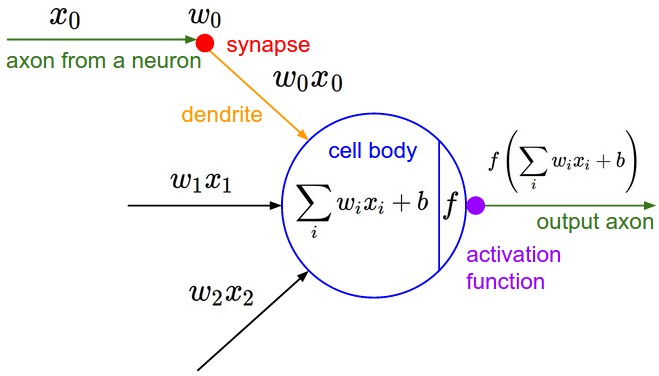

Example only contains one neuron - a neural network will have several connected neurons and a loss function

In [162]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# synaptic strengths (weights) of a neuron
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of neuron
b = Value(6.88, label='b')

x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1+x2w2'

n = x1w1x2w2 + b; n.label='n'
o = n.tanh(); o.label = 'o'
o.backward()

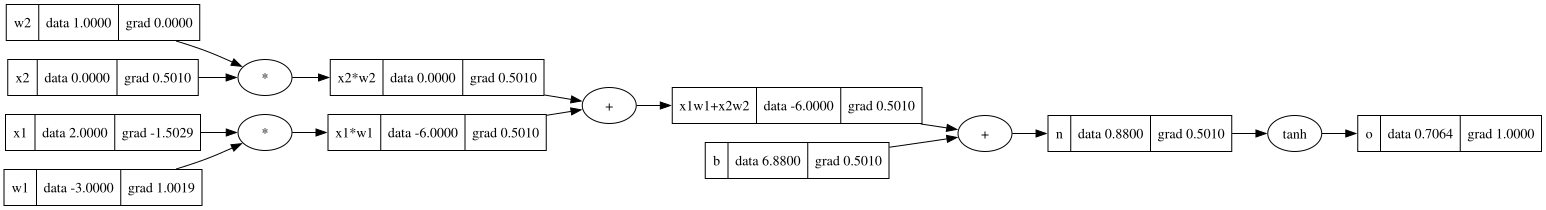

In [163]:
draw_dot(o)

In [ ]:
#1. To start backprop through tanh, what is local deriv of tanh?
# o = tanh(n)
# do/dn = 1 - o^2

#2. Plus operation distributes the gradient --> the local derivative of plus operation is 1, thus:
#   (x1w1 + x2w2).grad = 0.5 && b.grad = 0.5

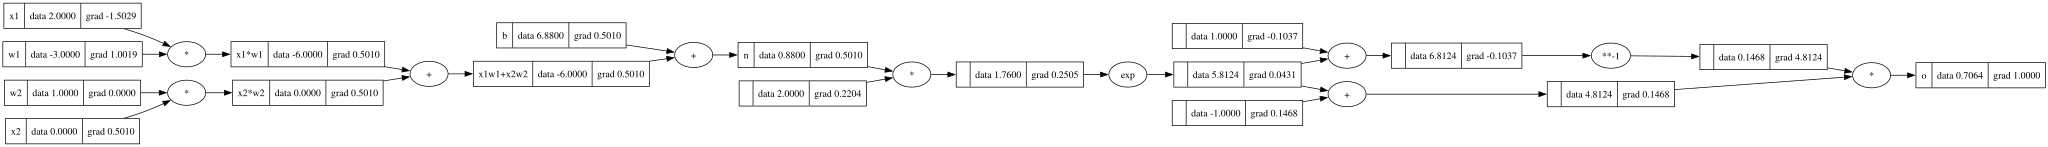

In [166]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# synaptic strengths (weights) of a neuron
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of neuron
b = Value(6.88, label='b')

x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1+x2w2'

n = x1w1x2w2 + b; n.label='n'

# ------
e = (2*n).exp()
o = (e - 1) / (e + 1)
# ------

o.label = 'o'
o.backward()
draw_dot(o)

In [ ]:
import torch

# tensor: n-dimensional array of scalars

In [198]:
import random

# Foundation
class Neuron:
    # nin - num inputs per neuron
    # w = weight - random num for each input
    # b = bias - controls "trigger happiness" of each neuron
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))
    
    def __call__(self, x):
        # activation = w * x + b
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out
    
    def parameters(self):
        return self.w + [self.b]
    
# Layer is a group of neurons
class Layer:
    # nout - num of neurons in a single layer
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
    
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
    
class MLP:
    # nouts - sizes of all layers in MLP
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i + 1]) for i in range(len(nouts))] 
        # self.layers = [Layer(a, b) for a, b in zip(sz, sz[1:])] --> same but with zip()

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    
    def paramters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [203]:
n.paramters()

[Value(data=-0.7306889373874119),
 Value(data=0.9938164140827264),
 Value(data=-0.4057190122053158),
 Value(data=-0.5327430402878535),
 Value(data=-0.025281470730851963),
 Value(data=0.8267063272237021),
 Value(data=-0.7440401299775234),
 Value(data=-0.6266939315589277),
 Value(data=-0.9614545596570687),
 Value(data=-0.26333457411466354),
 Value(data=0.26926703222256587),
 Value(data=0.8357700136299069),
 Value(data=0.9444436353804528),
 Value(data=0.4529549795670702),
 Value(data=0.905177210688678),
 Value(data=-0.713601778026701),
 Value(data=-0.4777329908540193),
 Value(data=0.5819294749454846),
 Value(data=-0.2710998761858623),
 Value(data=-0.5813602627929213),
 Value(data=-0.7009156216445178),
 Value(data=-0.49294152708118766),
 Value(data=-0.16617711704855975),
 Value(data=-0.2260877173652076),
 Value(data=0.854360651411491),
 Value(data=0.7818447694074862),
 Value(data=-0.2947804795281894),
 Value(data=-0.4381640103353619),
 Value(data=-0.36942792599652274),
 Value(data=-0.70833

In [200]:
# tiny dataset and loss function example
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0] # desired targets
ypred = [n(x) for x in xs]
ypred

[Value(data=0.974758266543789),
 Value(data=0.7816052169390734),
 Value(data=0.8953510180595571),
 Value(data=0.9296403550761148)]

In [201]:
# how do we tune neural nets weights to achieve desired targets?
# in deep learning, this is done by calculating the loss
# loss - a single number that measures performance of the total network

loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=6.772060255425612)

In [202]:
loss.backward()

In [196]:
n.layers[0].neurons[0].w[0].grad

3.4072926874886083

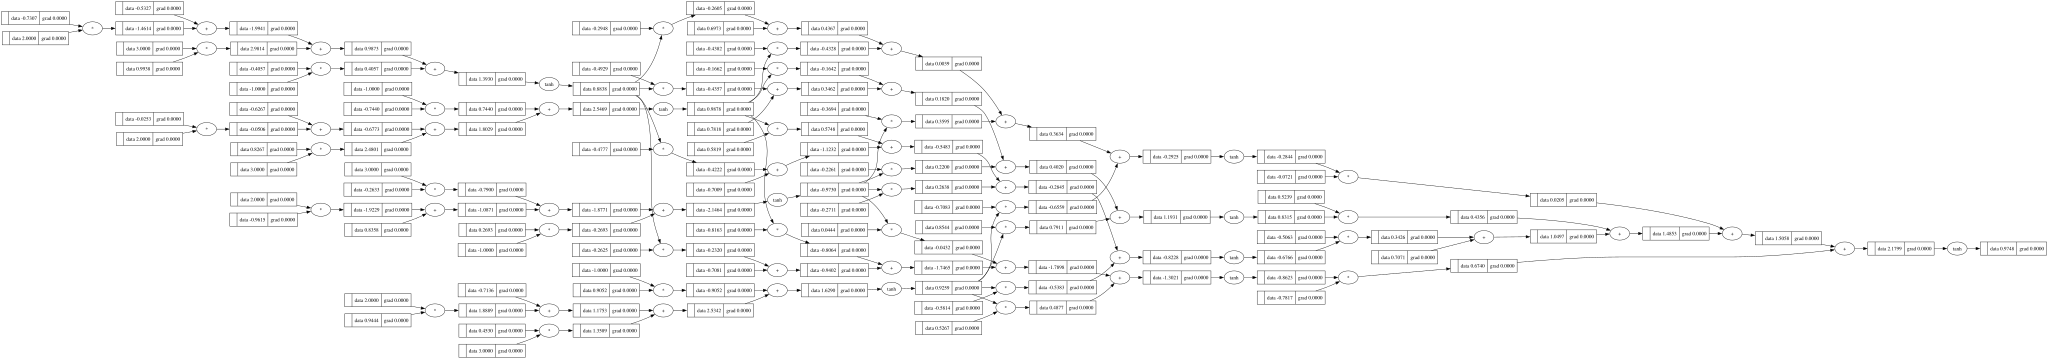

In [199]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)
draw_dot(n(x))